# Figure 1: JUMP Phenotypic Map

Combines map evaluation metrics (batch effects, reproducibility, biological recall) with UMAP visualizations of the JUMP phenotypic map across sources and bioactive compounds.

This notebook generates:

**Part A — Map Evaluation:**
1. Batch effects KS statistic heatmap (Source, Batch, Plate)
2. Reproducibility KS statistic heatmap (Perturbation)
3. Global biological recall heatmap (OpenTarget Gene/MoA)
4. Local biological recall heatmap (OpenTarget Gene/MoA)

**Part B — UMAP Visualizations:**
5. UMAP of batch-corrected (TVN) DINO features colored by source
6. UMAP of raw DINO features colored by source
7. UMAP of top MoAs (bioactive compounds)
8. UMAP of bioactive compounds colored by source
9. GNEprop scaffold cluster UMAP

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from collections import defaultdict
from tqdm import tqdm

import scanpy as sc
import umap
import anndata
from anndata import AnnData
import colorcet as cc

from rdkit.Chem import AllChem

from phenocompass.data.dataset import FastH5DatasetJUMP
from phenocompass.evaluation import reproducibility_ks, multivariate_metric_all, compute_per_term_metrics

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

%matplotlib inline

# --- Base directories ---
BASE_DIR = str(REPO_ROOT)

# --- Matplotlib configuration ---
setup_publication_style(BASE_DIR)

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "jump_phenotypic_map")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "jump_phenotypic_map")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# --- Final data directory ---
FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")
GROUND_TRUTH_DIR = os.path.join(FINAL_DATA_DIR, "jump_map")

# --- Morgan fingerprint featurizer ---
fpgen = AllChem.GetMorganGenerator(radius=3, fpSize=2048)
mf_featurizer = fpgen.GetCountFingerprint

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

# --- Control flag ---
FORCE_RECOMPUTE = False

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Dataset Configuration

In [2]:
# Dataset configurations
dataset_configs = {
    "dino_tvn": {
        "display_name": "DINO ViT\n(Batch Correction)",
        "embedding_file": os.path.join(FINAL_DATA_DIR, "jump_map", "jump_mapv3a_dino1_tvn.parquet"),
    },
    "cp_pca_tvn": {
        "display_name": "CellProfiler\n(Batch Correction)",
        "embedding_file": os.path.join(GROUND_TRUTH_DIR, "jump_mapv3a_cp_pca_tvn.parquet"),
    },
    "dino_raw": {
        "display_name": "DINO ViT",
        "embedding_file": os.path.join(GROUND_TRUTH_DIR, "jump_mapv3a_dino1.parquet"),
    },
    "cp_pca_raw": {
        "display_name": "CellProfiler",
        "embedding_file": os.path.join(GROUND_TRUTH_DIR, "jump_mapv3a_cp_pca.parquet"),
    },
}

ground_truth_configs = {
    "opentarget_target": {
        "display_name": "OpenTarget\n(Gene)",
        "file": os.path.join(GROUND_TRUTH_DIR, "opentarget_target.graph.pkl"),
    },
    "opentarget_moa": {
        "display_name": "OpenTarget\n(MoA)",
        "file": os.path.join(GROUND_TRUTH_DIR, "opentarget_moa.graph.pkl"),
    },
}

# Display name mappings
dataset_name_dict = {k: v["display_name"] for k, v in dataset_configs.items()}
multivariate_gt_dict = {k: v["display_name"] for k, v in ground_truth_configs.items()}

# Ordered dataset list
datasets = ["dino_tvn", "cp_pca_tvn", "dino_raw", "cp_pca_raw"]

## 3. Compute Evaluation Metrics (Optional)

This section computes metrics from raw embeddings when `FORCE_RECOMPUTE=True`.
Otherwise, it uses pre-computed results from `data/jump_phenotypic_map/`.

In [3]:
# Variables to evaluate for reproducibility
repro_variables = [
    "Metadata_JCP2022",
    "Metadata_Source",
    "Metadata_Batch",
    "Metadata_Plate",
    "Metadata_Perturbation",
]

# Ground truth files for multivariate metrics
gt_files = ["opentarget_target.graph.pkl", "opentarget_moa.graph.pkl"]

if FORCE_RECOMPUTE:
    print("Computing metrics from raw embeddings...")
    print("WARNING: This will take a long time (~30 min per dataset)")
    
    for dataset_key in tqdm(datasets, desc="Datasets"):
        config = dataset_configs[dataset_key]
        embedding_file = config["embedding_file"]
        
        print(f"\nProcessing {dataset_key}...")
        
        # Load embeddings
        df = pd.read_parquet(embedding_file)
        print(f"  Loaded {len(df)} samples")
        
        # Get feature columns
        feature_columns = [c for c in df.columns if not c.startswith("Metadata_")]
        print(f"  {len(feature_columns)} feature columns")
        
        # --- Reproducibility KS ---
        repro_cache = os.path.join(DATA_DIR, f"{dataset_key}.reproducibility_ks.csv")
        if not os.path.exists(repro_cache):
            print(f"  Computing reproducibility KS...")
            repro_df = reproducibility_ks(
                df,
                variables=repro_variables,
                n_samples=10000,
                columns=feature_columns,
            )
            repro_df.to_csv(repro_cache, index=False)
            print("  Saved")
        
        # --- Multivariate metrics ---
        # Aggregate to perturbation level
        df_agg = df.groupby("Metadata_Perturbation")[feature_columns].mean().reset_index()
        print(f"  Aggregated to {len(df_agg)} perturbations")
        
        for gt_file in gt_files:
            gt_key = gt_file.replace(".graph.pkl", "")
            mv_cache = os.path.join(DATA_DIR, f"{dataset_key}.multivariate_metrics.{gt_key}.csv")
            
            if not os.path.exists(mv_cache):
                print(f"  Computing multivariate metrics for {gt_key}...")
                results = multivariate_metric_all(
                    df_agg,
                    pert_field="Metadata_Perturbation",
                    data_dir=GROUND_TRUTH_DIR,
                    eval_datasets=[gt_file],
                    columns=feature_columns,
                    distance_metric="cosine",
                    sample_size_global=10000,
                    sample_size_local=1000,
                    test_universe="ground_truth",
                )
                for key, result_df in results.items():
                    result_df.to_csv(mv_cache, index=False)
                    print("  Saved")
        
        # Free memory
        del df, df_agg
    
    print("\nMetric computation complete!")
else:
    print("Using pre-computed metrics from data/jump_phenotypic_map/")
    print("Set FORCE_RECOMPUTE=True to recompute from raw embeddings")

Using pre-computed metrics from data/jump_phenotypic_map/
Set FORCE_RECOMPUTE=True to recompute from raw embeddings


### 3b. Compute Per-Term MoA Metrics (Optional)

Computes per-MoA-term AUROC and AP using the DINO TVN embeddings and `opentarget_moa` ground truth.
This is used later (Section 13) for the top-MoA bar chart and UMAP coloring.

In [4]:
perterm_cache = os.path.join(DATA_DIR, "dino_tvn.per_term_moa_metrics.csv")

if FORCE_RECOMPUTE and not os.path.exists(perterm_cache):
    dataset_key = "dino_tvn"
    config = dataset_configs[dataset_key]

    print(f"Computing per-term MoA metrics for {dataset_key}...")
    df = pd.read_parquet(config["embedding_file"])
    feature_columns = [c for c in df.columns if not c.startswith("Metadata_")]
    df_agg = df.groupby("Metadata_Perturbation")[feature_columns].mean().reset_index()
    print(f"  Loaded {len(df)} samples, aggregated to {len(df_agg)} perturbations")

    gt_path = os.path.join(GROUND_TRUTH_DIR, "opentarget_moa.graph.pkl")
    with open(gt_path, "rb") as f:
        gt_data = pickle.load(f)

    perterm_df = compute_per_term_metrics(
        df_agg,
        pert_field="Metadata_Perturbation",
        gt_sets=gt_data["sets"],
        columns=feature_columns,
        distance_metric="cosine",
        max_fprs=[None, 0.1],
    )
    perterm_df.to_csv(perterm_cache, index=False)
    print(f"  Saved per-term MoA metrics ({len(perterm_df)} rows)")
    del df, df_agg
else:
    print("Per-term MoA metrics cached at")

Per-term MoA metrics cached at


## 4. Load Evaluation Data

In [5]:
load_dir = DATA_DIR
print("Loading metrics from")

# --- Load multivariate metrics ---
percentile = 95
global_metric = "global_recall_one-sided"
local_metric = "local_recall_one-sided"

multivariate_dict = defaultdict(list)
for dataset_key in datasets:
    for gt_key in ["opentarget_target", "opentarget_moa"]:
        outpath = os.path.join(load_dir, f"{dataset_key}.multivariate_metrics.{gt_key}.csv")
        df = pd.read_csv(outpath)
        multivariate_dict["dataset"].append(dataset_key)
        multivariate_dict["ground_truth"].append(gt_key)
        multivariate_dict[global_metric].append(
            df[df["percentile"] == percentile][global_metric].values[0]
        )
        multivariate_dict[local_metric].append(
            df[df["percentile"] == percentile][local_metric].values[0]
        )

multivariate_df = pd.DataFrame(multivariate_dict)
multivariate_df.sort_values(by=["dataset", "ground_truth"], inplace=True)
multivariate_df["dataset"] = multivariate_df["dataset"].map(dataset_name_dict)
multivariate_df["ground_truth"] = multivariate_df["ground_truth"].map(multivariate_gt_dict)
print(f"Loaded multivariate metrics: {len(multivariate_df)} rows")

# --- Load reproducibility KS statistics ---
reproducibility_df_list = []
for dataset_key in datasets:
    outpath = os.path.join(load_dir, f"{dataset_key}.reproducibility_ks.csv")
    df = pd.read_csv(outpath)
    df["dataset"] = dataset_key
    reproducibility_df_list.append(df)
reproducibility_df = pd.concat(reproducibility_df_list, ignore_index=True)

# Filter to relevant variables
reproducibility_df = reproducibility_df[reproducibility_df["variable"].isin(
    ["Metadata_Perturbation", "Metadata_Plate", "Metadata_Batch", "Metadata_Source"]
)]
reproducibility_df.sort_values(by=["dataset"], inplace=True)
reproducibility_df["dataset"] = reproducibility_df["dataset"].map(dataset_name_dict)

reproducibility_pivot_df = reproducibility_df.pivot(
    columns="dataset", index="variable", values="statistic"
)
reproducibility_pivot_df.index = [
    n.split("Metadata_")[1] for n in reproducibility_pivot_df.index
]
print("Loaded reproducibility stats")

Loading metrics from


Loaded multivariate metrics: 8 rows
Loaded reproducibility stats


## 5. Batch Effects Heatmap

Figure already exists


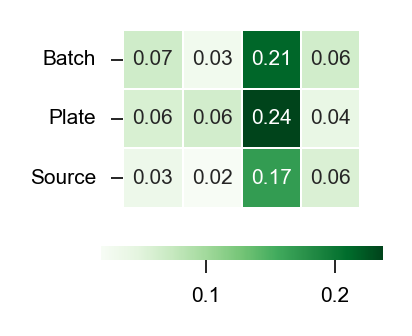

In [6]:
fig_path = os.path.join(FIGURE_DIR, "Fig1_batch_effects.heatmap.colorbar.pdf")

plt.figure(figsize=(1.1, 1.1))
hm = sns.heatmap(
    reproducibility_pivot_df.loc[reproducibility_pivot_df.index.values != "Perturbation"],
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True,
    cmap="Greens",
    linecolor="white",
    linewidths=0.1,
    annot_kws={"size": 5},
    xticklabels=False,
    cbar_kws={"orientation": "horizontal", "shrink": 1.1},
)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.xlabel("")
plt.ylabel("")
hm.set_xticklabels([])
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=5)

save_figure(fig_path, FORCE_RECOMPUTE)

## 6. Reproducibility Heatmap

Figure already exists


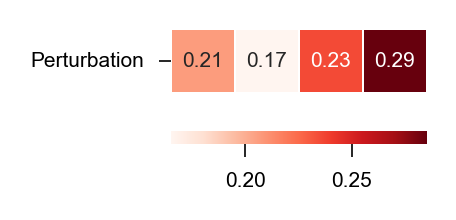

In [7]:
fig_path = os.path.join(FIGURE_DIR, "Fig1_reproducibility.heatmap.colorbar.pdf")

plt.figure(figsize=(1.1, 1.1))
hm = sns.heatmap(
    reproducibility_pivot_df.loc[["Perturbation"]],
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True,
    cmap="Reds",
    linecolor="white",
    linewidths=0.1,
    xticklabels=False,
    cbar_kws={"orientation": "horizontal", "shrink": 1.0},
    annot_kws={"size": 5},
)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.xlabel("")
plt.ylabel("")
hm.set_xticklabels([])
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=5)

save_figure(fig_path, FORCE_RECOMPUTE)

## 7. Biological Recall Heatmaps

Figure already exists


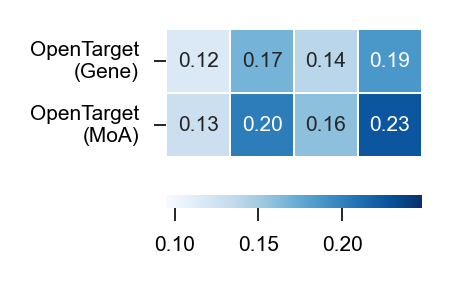

In [8]:
# Compute shared vmin/vmax for consistent color scaling
vmin = min(
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="global_recall_one-sided"
    ).values.min(),
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="local_recall_one-sided"
    ).values.min(),
)
vmax = max(
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="global_recall_one-sided"
    ).values.max(),
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="local_recall_one-sided"
    ).values.max(),
)

# Global recall heatmap
fig_path = os.path.join(FIGURE_DIR, "Fig1_biological_recall.global.heatmap.colorbar.pdf")

plt.figure(figsize=(1.1, 1.1))
hm = sns.heatmap(
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="global_recall_one-sided"
    ),
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True,
    cmap="Blues",
    linecolor="white",
    linewidths=0.1,
    xticklabels=False,
    cbar_kws={"orientation": "horizontal", "shrink": 1},
    annot_kws={"size": 5},
    vmin=0.9 * vmin,
    vmax=1.1 * vmax,
)
plt.xticks(rotation=45)
plt.ylabel("")
plt.xlabel("")
hm.set_xticklabels([])
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=5)

save_figure(fig_path, FORCE_RECOMPUTE)

Figure already exists


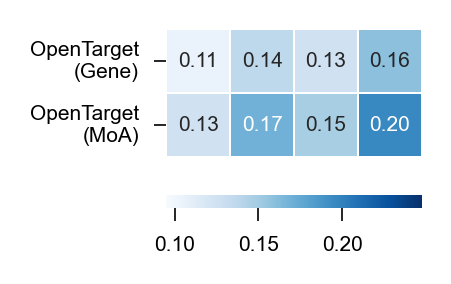

In [9]:
# Local recall heatmap
fig_path = os.path.join(FIGURE_DIR, "Fig1_biological_recall.local.heatmap.colorbar.pdf")

plt.figure(figsize=(1.1, 1.1))
hm = sns.heatmap(
    multivariate_df.pivot(
        columns="dataset", index="ground_truth", values="local_recall_one-sided"
    ),
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True,
    cmap="Blues",
    linecolor="white",
    linewidths=0.1,
    xticklabels=False,
    cbar_kws={"orientation": "horizontal", "shrink": 1},
    annot_kws={"size": 5},
    vmin=0.9 * vmin,
    vmax=1.1 * vmax,
)
plt.xticks(rotation=45)
plt.ylabel("")
plt.xlabel("")
hm.set_xticklabels([])
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=5)

save_figure(fig_path, FORCE_RECOMPUTE)

## 8. Save Map Evaluation Figure Source Data

In [10]:
# Save figure source data for manuscript reproducibility

# --- Batch effects and reproducibility KS statistics ---
batch_repro_reset = reproducibility_pivot_df.reset_index()
index_col = batch_repro_reset.columns[0]
batch_repro_reset = batch_repro_reset.rename(columns={index_col: "variable"})
batch_repro_long = batch_repro_reset.melt(
    id_vars="variable", var_name="dataset", value_name="ks_statistic"
)
batch_repro_long["metric_type"] = batch_repro_long["variable"].apply(
    lambda x: "reproducibility" if x == "Perturbation" else "batch_effects"
)

fig_data_path = os.path.join(FIGURE_DIR, "Fig1_maplib_batch_reproducibility_data.tsv")
save_figure_data(batch_repro_long, fig_data_path, FORCE_RECOMPUTE)

# --- Biological recall data ---
recall_long = multivariate_df.copy()
fig_data_path = os.path.join(FIGURE_DIR, "Fig1_maplib_biological_recall_data.tsv")
save_figure_data(recall_long, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists
Figure data already exists


## 9. Dataset and Embedding Loading

In [11]:
h5_path = os.path.join(FINAL_DATA_DIR, "jump_map/jump_dino_tvn.h5")
index_predetermined_file = os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_cluster_splits.pkl")
dataset = FastH5DatasetJUMP(h5_path, avg_morph_feat=True, index_predetermined_file=index_predetermined_file,
                            ohe_batch=False, struct_ipt="fixed",
                            fixed_struct_data=os.path.join(FINAL_DATA_DIR, "embeddings/structure/gneprop_embeddings.parquet"))

In [12]:
file_path = os.path.join(FINAL_DATA_DIR, "embeddings/image/dino_image_embeddings.parquet")
img_representations_df = pd.read_parquet(file_path)

## 10. UMAP of Batch-Corrected (TVN) DINO Features

Loaded cached TVN UMAP data
Figure already exists


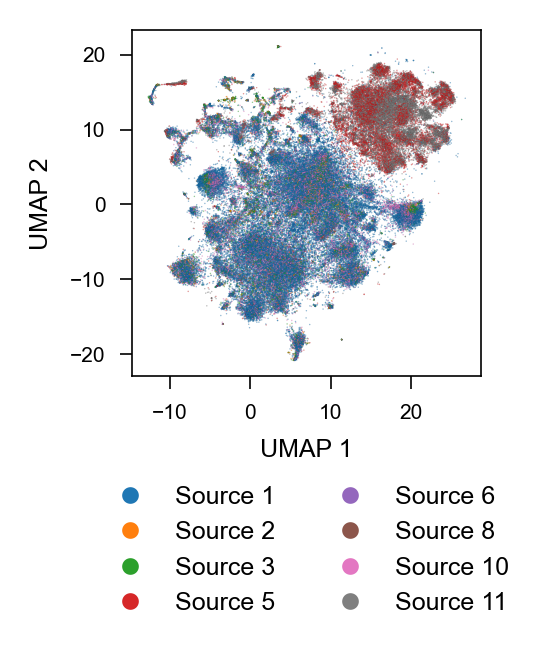

In [13]:
save_dir = os.path.join(FINAL_DATA_DIR, "jump_map")
data_path = os.path.join(DATA_DIR, "umap_dino1_tvn_by_source.csv")

if os.path.exists(data_path):
    data_df = pd.read_csv(data_path, index_col=0)
    print("Loaded cached TVN UMAP data")
else:
    adata = sc.read(os.path.join(save_dir, "dino_tvn_morphology.h5ad"))
    adata.obsm["X_umap"] = umap.UMAP(
        n_neighbors=25, min_dist=0.2, negative_sample_rate=40, repulsion_strength=1.5, metric="cosine",
        random_state=0
    ).fit_transform(adata.X)

    data_df = pd.DataFrame(adata.obsm["X_umap"], columns=["umap_1", "umap_2"], index=dataset.ids)
    data_df["most_common_source"] = [int(n.split("_")[1]) for n in adata.obs["most_common_source"].values]
    data_df.to_csv(data_path)
    print("TVN UMAP data saved")

lut = dict(zip(set(data_df["most_common_source"].unique()),
           sns.color_palette("tab10")))
data_df["colors"] = data_df["most_common_source"].map(lut).values

np.random.seed(0)
random_idx = np.arange(len(data_df))
np.random.shuffle(random_idx)

data_df = data_df.iloc[random_idx]

plt.figure(figsize=(1.5, 1.5))
plt.scatter(data_df["umap_1"], data_df["umap_2"], s=0.1, alpha=0.5, c=data_df["colors"],
            edgecolor="black", linewidth=0.01, rasterized=True)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

legend_elements = [Line2D([0], [0], marker='o', color="w", label='Source {}'.format(source_idx),
                   markerfacecolor=lut[source_idx], markersize=5) for source_idx in sorted(data_df["most_common_source"].unique())]

leg = plt.legend(handles=legend_elements, bbox_to_anchor=(0.5, -0.25), loc="upper center", ncol=2)

plot_path = os.path.join(FIGURE_DIR, "FigS2_dino1_tvn_by_source_umap.pdf")
save_figure(plot_path, FORCE_RECOMPUTE)

## 11. UMAP of Raw DINO Features (No Batch Correction)

Loaded cached raw DINO UMAP data
Figure already exists


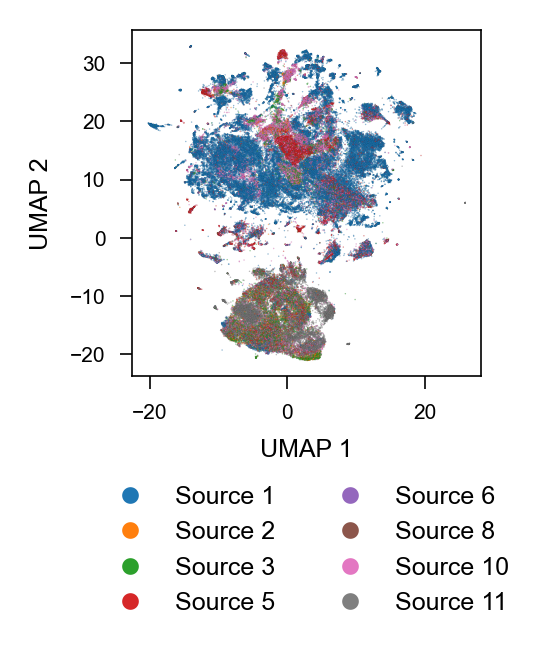

In [14]:
save_dir = os.path.join(FINAL_DATA_DIR, "jump_map")
data_path = os.path.join(DATA_DIR, "umap_dino1_raw_by_source.csv")

if os.path.exists(data_path):
    data_df = pd.read_csv(data_path, index_col=0)
    print("Loaded cached raw DINO UMAP data")
else:
    adata = sc.read(os.path.join(save_dir, "dino_raw_morphology.h5ad"))
    adata.obsm["X_umap"] = umap.UMAP(
        n_neighbors=25, min_dist=0.2, negative_sample_rate=40, repulsion_strength=1.5, metric="cosine",
        random_state=0
    ).fit_transform(adata.X)

    data_df = pd.DataFrame(adata.obsm["X_umap"], columns=["umap_1", "umap_2"], index=dataset.ids)
    data_df["most_common_source"] = [int(n.split("_")[1]) for n in adata.obs["most_common_source"].values]
    data_df.to_csv(data_path)
    print("Raw DINO UMAP data saved")

lut = dict(zip(set(data_df["most_common_source"].unique()),
           sns.color_palette("tab10")))
data_df["colors"] = data_df["most_common_source"].map(lut).values

np.random.seed(0)
random_idx = np.arange(len(data_df))
np.random.shuffle(random_idx)

data_df = data_df.iloc[random_idx]

plt.figure(figsize=(1.5, 1.5))
plt.scatter(data_df["umap_1"], data_df["umap_2"], s=0.1, alpha=0.5, c=data_df["colors"],
            edgecolor="black", linewidth=0.01, rasterized=True)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
legend_elements = [Line2D([0], [0], marker='o', color="w", label='Source {}'.format(source_idx),
                   markerfacecolor=lut[source_idx], markersize=5) for source_idx in sorted(data_df["most_common_source"].unique())]

leg = plt.legend(handles=legend_elements, bbox_to_anchor=(0.5, -0.25), loc="upper center", ncol=2)

plot_path = os.path.join(FIGURE_DIR, "FigS2_dino1_by_source_umap.pdf")
save_figure(plot_path, FORCE_RECOMPUTE)

## 12. Load Annotation Data & Bioactive Compounds

In [15]:
smiles_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "compound_annotations/jump_inchikey_smiles.tsv"), sep="\t")
inchikey_to_smile_dict = dict(zip(smiles_df["Metadata_Perturbation"], smiles_df["Metadata_smile"]))

In [16]:
annotations_dir = os.path.join(FINAL_DATA_DIR, "jump_map")
eval_datasets = ["opentarget_target.graph.pkl", "opentarget_moa.graph.pkl"]

with open(os.path.join(annotations_dir, eval_datasets[0]), "rb") as f:
    gene_target_graph = pickle.load(f)

with open(os.path.join(annotations_dir, eval_datasets[1]), "rb") as f:
    moa_target_graph = pickle.load(f)

# Update the target graph with SMILES strings
updated_moa_smiles_graph = {k: [inchikey_to_smile_dict[n] for n in mol_list if n in inchikey_to_smile_dict]
                            for k, mol_list in moa_target_graph["sets"].items()}

# Build MoA-to-SMILES DataFrame
updated_moa_smiles_data_dict = defaultdict(list)
for moa, smiles_list in updated_moa_smiles_graph.items():
    for smiles in smiles_list:
        updated_moa_smiles_data_dict["moa"].append(moa)
        updated_moa_smiles_data_dict["smiles"].append(smiles)
updated_moa_smiles_df = pd.DataFrame(updated_moa_smiles_data_dict)

In [17]:
bioactivity_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "jump_map/jump_bioactivity_predictions.tsv"), sep="\t")
bioactivity_df.index = bioactivity_df["Metadata_SMILES"].values

print("Proportion of bioactive compounds:", bioactivity_df["significant_bh"].mean())
bioactive_compounds = bioactivity_df[bioactivity_df["significant_bh"]]["Metadata_SMILES"].values

Proportion of bioactive compounds: 0.27639751552795033


## 13. Multivariate Metrics & Top MoAs

In [18]:
def update_annotation_label(n):

    if "sodium-chloride cotransporter" in n:
        n = n.replace("sodium-chloride cotransporter", "NCC")
    
    if " alpha-1" in n:
        return n.replace(" alpha-1", "\nalpha-1")
    elif "Dual specificity mitogen-activated protein kinase kinase " in n:
        return "MAP2K1/2 inhibitor"
    elif "Cyclin-dependent kinase " in n:
        return "CDK1/2/4 inhibitor"
    elif "Cytochrome P450 51" in n:
        return n.replace("Cytochrome P450 51", "CYP51")
    elif "Heat shock protein " in n:
        return n.replace("Heat shock protein ", "")
    elif " receptor" in n:
        return n.replace(" receptor", "\nreceptor")
    elif "transporter" in n:
        return n.replace("transporter", "\ntransporter")
    elif "alpha" in n:
        return n.replace("alpha", "\nalpha")
    elif " kinase" in n:
        return n.replace(" kinase", "\nkinase")
    elif " inhibitor" in n:
        return n.replace(" inhibitor", "\ninhibitor")
    
    return n

In [19]:
perterm_moa_df = pd.read_csv(os.path.join(DATA_DIR, "dino_tvn.per_term_moa_metrics.csv"))

local_ap_df = perterm_moa_df[(perterm_moa_df["metric"] == "AP") & (perterm_moa_df["locality"] == "local")]
print("Local mAP: {:.3f}".format(local_ap_df["value"].mean()))

global_auroc_df = perterm_moa_df[
    (perterm_moa_df["metric"] == "AUROC") &
    (perterm_moa_df["locality"] == "global") &
    (perterm_moa_df["max_fpr"] == 0.1)
]
moa_mean_auroc_df = global_auroc_df[["term", "value", "n_compounds"]].copy()
moa_mean_auroc_df = moa_mean_auroc_df.sort_values("value", ascending=False).reset_index(drop=True)

Local mAP: 0.148


In [20]:
moa_to_keep = moa_mean_auroc_df[
    (moa_mean_auroc_df["n_compounds"] >= 3) & (moa_mean_auroc_df["n_compounds"] <= 100)
]["term"].values
moa_mean_auroc_df = moa_mean_auroc_df[moa_mean_auroc_df["term"].isin(moa_to_keep)]

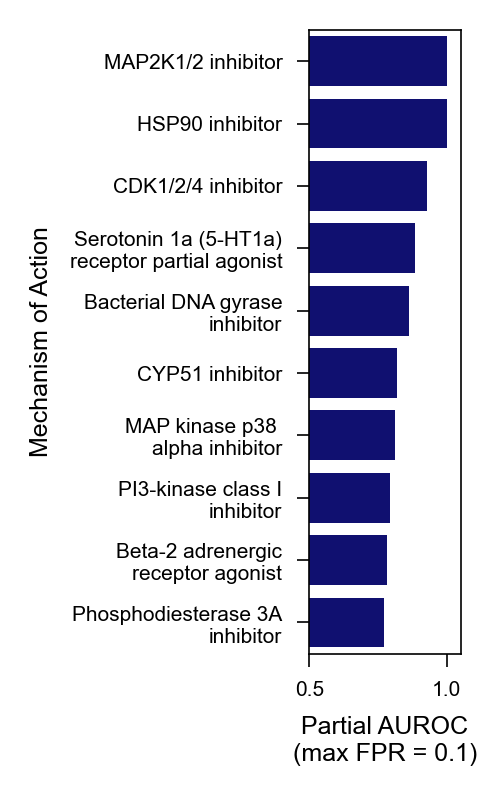

In [21]:
plot_df = moa_mean_auroc_df.head(13)
plot_df["term"] = plot_df["term"].apply(update_annotation_label)
plot_df.sort_values("value", inplace=True, ascending=False)

plot_df.drop_duplicates(subset="term", keep="first", inplace=True)
plt.figure(figsize=(0.65, 2.7))
sns.barplot(x="value", y="term", data=plot_df, color="navy")
plt.xlim([0.5, 1.05])
plt.xlabel("Partial AUROC\n(max FPR = 0.1)")
plt.ylabel("Mechanism of Action")
plt.show()

## 14. Visualization of Top MoAs

In [22]:
# Load the morphology AnnData for color mapping reference
save_dir = os.path.join(FINAL_DATA_DIR, "jump_map")
morph_adata = sc.read(os.path.join(save_dir, "dino_tvn_morphology.h5ad"))
morph_adata.obs["most_common_source"] = [int(n.split("_")[1]) for n in morph_adata.obs["most_common_source"].values]

lut = dict(zip(sorted(morph_adata.obs["most_common_source"].unique().astype(int)),
               sns.color_palette("tab10")))

In [23]:
n_top_moas = 13
top_moa_by_auroc = moa_mean_auroc_df.sort_values("value", ascending=False).head(n_top_moas)["term"].values

adata = AnnData(img_representations_df)
adata.obs["Metadata_smile"] = img_representations_df.index.values

adata.obs["annotation"] = "Other"

for smile in adata.obs.index.values:
    for moa in top_moa_by_auroc:
        if moa in updated_moa_smiles_graph and smile in updated_moa_smiles_graph[moa]:
            adata.obs.loc[smile, "annotation"] = moa
            break

adata.obs["bioactive"] = adata.obs.index.isin(bioactive_compounds)
adata.obs["annotation"].value_counts()

annotation
Other                                                                   108783
MAP kinase p38 alpha inhibitor                                              11
PI3-kinase class I inhibitor                                                 8
Cytochrome P450 51 inhibitor                                                 7
Beta-2 adrenergic receptor agonist                                           6
Bacterial DNA gyrase inhibitor                                               4
Cyclin-dependent kinase 1 inhibitor                                          4
Dual specificity mitogen-activated protein kinase kinase 1 inhibitor         4
Phosphodiesterase 3A inhibitor                                               3
Serotonin 1a (5-HT1a) receptor partial agonist                               3
Heat shock protein HSP90 inhibitor                                           3
Name: count, dtype: int64

#### Visualize norms

<Axes: xlabel='norm', ylabel='Count'>

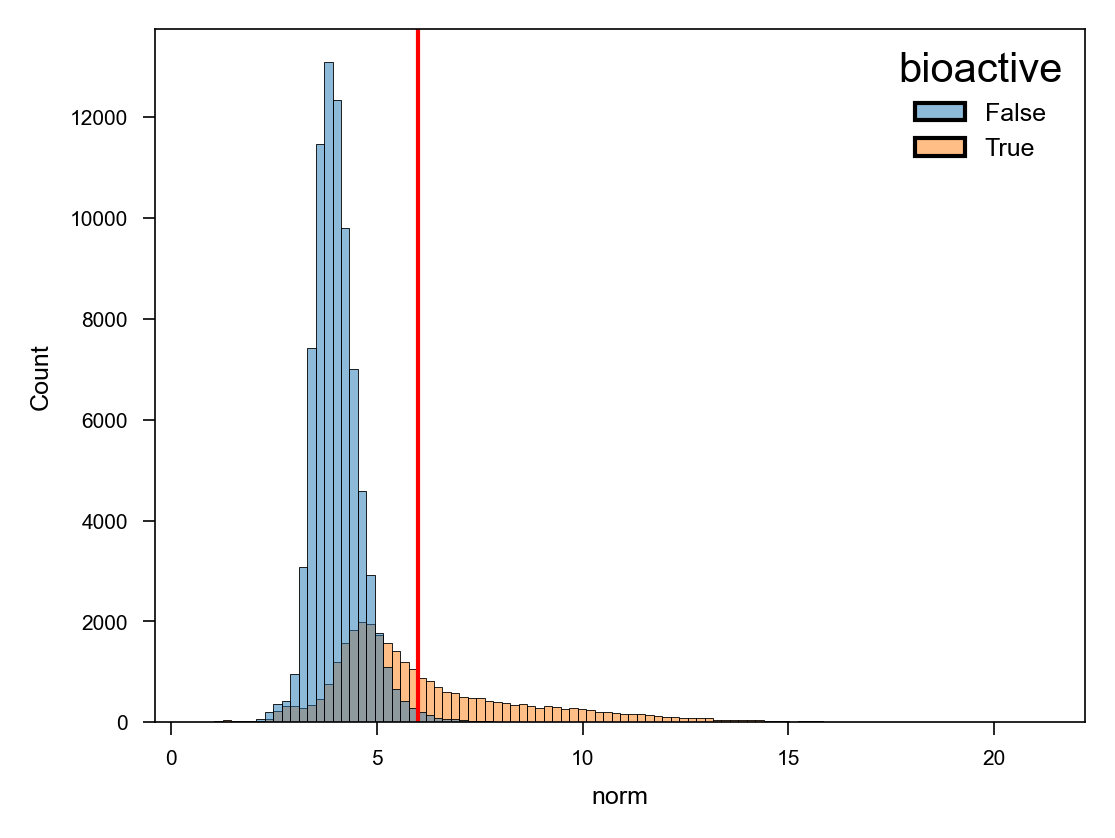

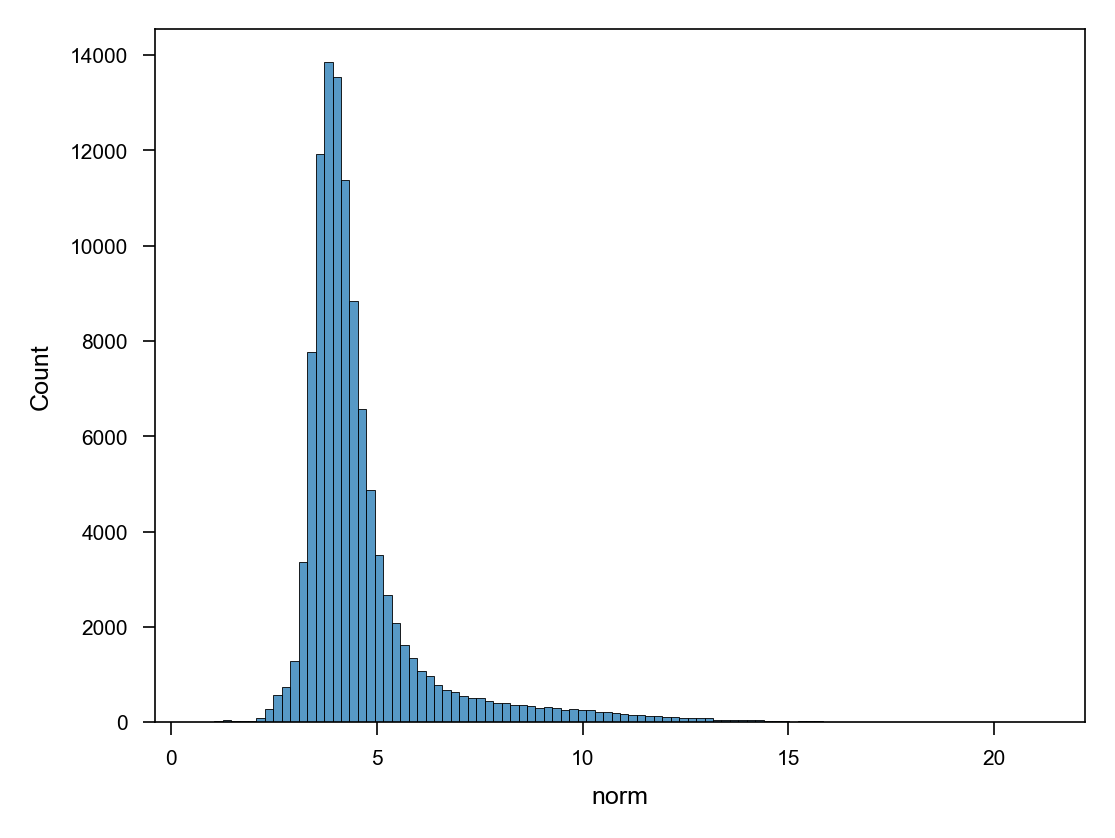

In [24]:
norm_df = pd.DataFrame(dict(norm=np.linalg.norm(adata.X, axis=1), bioactive=adata.obs["bioactive"]))
figsize = (4, 3)
fig, ax = plt.subplots(figsize=figsize)
sns.histplot(norm_df, x="norm", hue="bioactive", ax=ax, bins=100)
ax.axvline(6, c="r", linewidth=1.0)
fig, ax = plt.subplots(figsize=figsize)
sns.histplot(norm_df, x="norm", ax=ax, bins=100)

### Plotting code

In [25]:
def sample_disk(n_samples):
    thetas = np.random.uniform(0, 2*np.pi, n_samples)
    rs = np.sqrt(np.random.uniform(0, 1, n_samples))
    return np.column_stack((
        rs * np.cos(thetas),
        rs * np.sin(thetas)
    ))

def mitchell_best_candidates(starting_points, jitter_strength, num_candidates=3):
    points = np.zeros_like(starting_points)

    # Add first point at random
    points[0,:] = starting_points[0,:] + jitter_strength * sample_disk(1)
    
    # Generate remaining points
    for i in range(1, starting_points.shape[0]):
        # Generate candidate points
        candidates = starting_points[i,:] + jitter_strength * sample_disk(num_candidates)
        
        # Calculate distances from each candidate to all existing points
        existing_points = points[:i]
        
        # Find minimum distance for each candidate
        min_dists = np.min(np.sum((candidates[:,None,:] - existing_points[None,:,:])**2, axis=-1), axis=1)        
        # Select candidate with the largest minimum distance
        best_idx = np.argmax(min_dists)
        points[i] = candidates[best_idx]
    
    return points

def plot_annotation_umap(
    plot_df,
    hue_col=None,
    jitter_strength=0.15,
    figsize=(2., 2.),
    annot_kwargs=dict(s=4, hue="annotation", marker="o", edgecolor="black", alpha=1.0, linewidth=0.3),
    other_kwargs=dict(s=0.3, edgecolor=None, alpha=0.35, color="gray", palette="viridis"),
    embedding_name="UMAP",
    legend_markersize=4,
    save_path=None,
):
    emb_names = [f"{embedding_name}1", f"{embedding_name}2"]
    # Add jitter to annotated compounds
    jittered_points = (
        plot_df.query("annotation != 'Other'")
    ).copy()
    jittered_points[emb_names] = mitchell_best_candidates(
        jittered_points[emb_names].values,
        jitter_strength=jitter_strength,
        num_candidates=5
    )
    jittered_df = pd.concat([jittered_points, plot_df.query("annotation == 'Other'")])
    
    # Make plot
    fig, ax = plt.subplots(figsize=figsize)
    sns.scatterplot(
        jittered_df.query("annotation == 'Other'"), x=emb_names[0], y=emb_names[1], ax=ax,
        hue=hue_col,
        **other_kwargs
    )
    sns.scatterplot(
        jittered_df.query("annotation != 'Other'"), x=emb_names[0], y=emb_names[1], ax=ax,
        **annot_kwargs
    )
    leg = ax.legend(bbox_to_anchor=(1.2, -0.2), ncol=2)
    
    # Adjust legend size
    for handle in leg.legend_handles:
        handle.set_markersize(legend_markersize)
        if isinstance(handle._alpha, float):
            handle.set_alpha(1.0)

    if save_path is not None:
        save_figure(save_path, FORCE_RECOMPUTE)
    else:
        plt.show()

### Strong effect compounds + annotated compounds

In [26]:
# Produce anndata object for plotting
norm_cutoff = 6
adata.obs["norm"] = np.linalg.norm(adata.X, axis=1)
plot_adata = adata[adata.obs.query(
    "((index in @bioactive_compounds) & (norm > @norm_cutoff) & (annotation == 'Other')) | (annotation != 'Other')"
).index]

In [27]:
plot_adata.obsm["X_umap"] = umap.UMAP(
    n_neighbors=25, min_dist=0.2, negative_sample_rate=40, repulsion_strength=1.5, metric="cosine",
    random_state=0
).fit_transform(plot_adata.X)

In [28]:
plot_df = adata.obs.merge(
    pd.DataFrame(plot_adata.obsm["X_umap"], columns=["UMAP1", "UMAP2"]).set_index(plot_adata.obs.index),
    left_index=True, right_index=True
).pipe(
    lambda df: df.assign(annotation=df["annotation"].apply(update_annotation_label))
)

Figure already exists


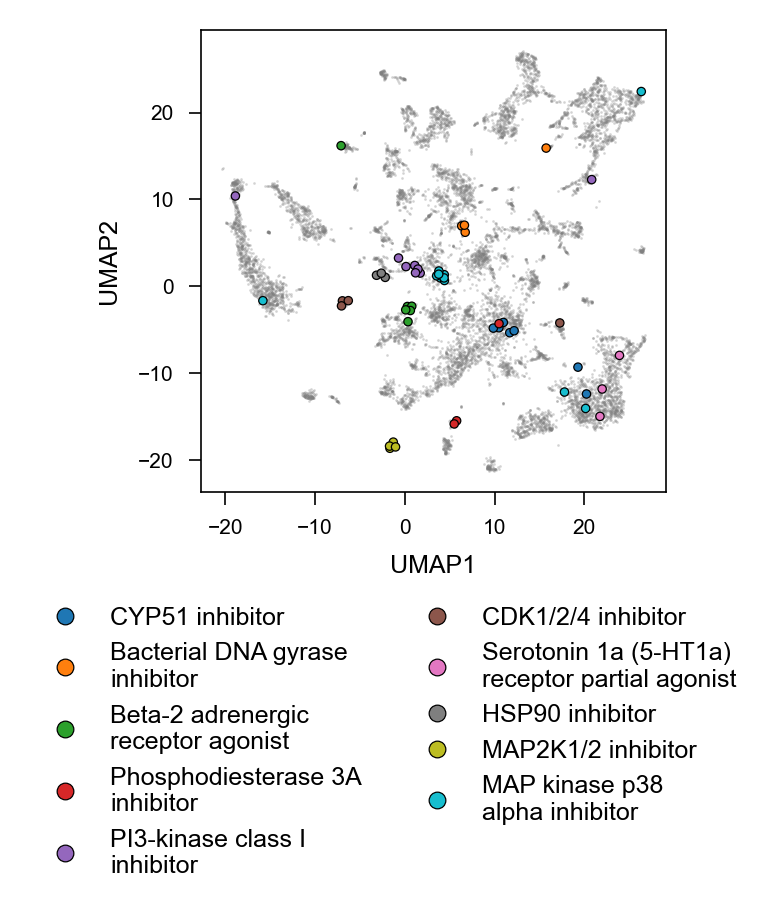

In [29]:
save_path = os.path.join(FIGURE_DIR, "Fig1_jump_mapv3a_dino1_tvn_umap_moa.pdf")
plot_annotation_umap(plot_df, hue_col=None, jitter_strength=0.5, save_path=save_path)

### Color by Source

Figure already exists


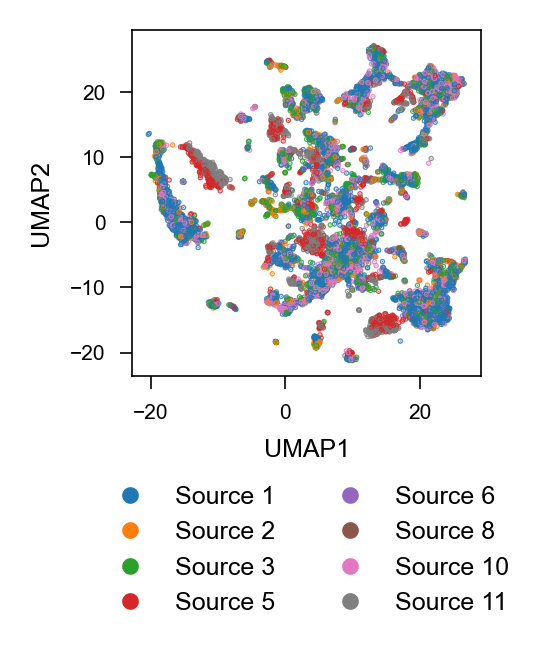

In [30]:
plot_df["most_common_source"] = plot_df["Metadata_smile"].map(morph_adata.obs["most_common_source"].to_dict())

data_df = plot_df.copy()
data_df["colors"] = data_df["most_common_source"].map(lut).values

np.random.seed(0)
random_idx = np.arange(len(data_df))
np.random.shuffle(random_idx)

data_df = data_df.iloc[random_idx]

plt.figure(figsize=(1.5, 1.5))
plt.scatter(data_df["UMAP1"], data_df["UMAP2"], s=0.1, alpha=0.8, c=data_df["colors"], marker="o")

legend_elements = [Line2D([0], [0], marker='o', color="w", label='Source {}'.format(source_idx),
                   markerfacecolor=lut[source_idx], markersize=5) for source_idx in sorted(data_df["most_common_source"].unique().astype(int))]

leg = plt.legend(handles=legend_elements, bbox_to_anchor=(0.5, -0.25), loc="upper center", ncol=2)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
fig_path = os.path.join(FIGURE_DIR, "FigS2_jump_mapv3a_dino1_tvn_umap_moa.by_source.bioactive_background.pdf")
save_figure(fig_path, FORCE_RECOMPUTE)

In [31]:
# Save figure source data for manuscript reproducibility
# Create consolidated AnnData with UMAP coordinates and metadata for all visualizations

# Load both UMAP sources
save_dir = os.path.join(FINAL_DATA_DIR, "jump_map")
tvn_adata = sc.read(os.path.join(save_dir, "dino_tvn_morphology.h5ad"))
raw_adata = sc.read(os.path.join(save_dir, "dino_raw_morphology.h5ad"))

# Create figure data AnnData
fig_adata = AnnData(obs=pd.DataFrame(index=dataset.ids))
fig_adata.obs["smiles"] = dataset.ids

# Add UMAP coordinates as obsm
fig_adata.obsm["X_umap_tvn"] = tvn_adata.obsm["X_umap"]
fig_adata.obsm["X_umap_raw"] = raw_adata.obsm["X_umap"]

# Add metadata
fig_adata.obs["most_common_source"] = [int(n.split("_")[1]) for n in tvn_adata.obs["most_common_source"].values]

# Add MoA annotation from plot_df if available
if 'plot_df' in dir():
    smiles_to_annotation = dict(zip(plot_df.index, plot_df["annotation"]))
    fig_adata.obs["annotation"] = [smiles_to_annotation.get(s, "Other") for s in fig_adata.obs.index]
    fig_adata.obs["bioactive"] = fig_adata.obs.index.isin(bioactive_compounds)

fig_data_path = os.path.join(FIGURE_DIR, "Fig1_S2_jump_batch_umap_data.h5ad")
if not os.path.exists(fig_data_path) or FORCE_RECOMPUTE:
    fig_adata.write_h5ad(fig_data_path)
    print("Saved figure data")
else:
    print("Figure data exists")

Figure data exists


## 15. GNEprop Scaffold Cluster UMAP

Figure already exists


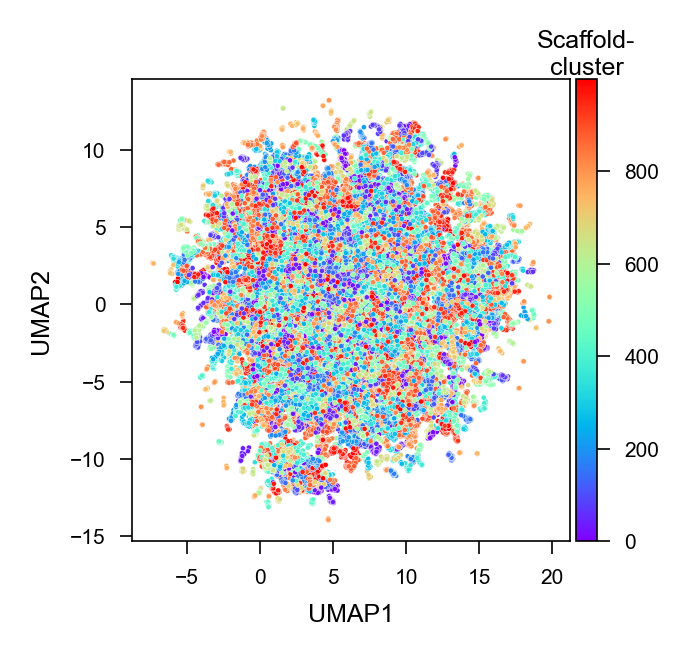

Figure data already exists


In [32]:
umap_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "jump_map/scaffold_clusters_umap.parquet"))

# Get the number of unique clusters
num_clusters = umap_df['cluster'].nunique()

# Use a continuous colormap to create a natural gradient for clusters
palette = sns.color_palette("rainbow", n_colors=num_clusters)

# Map cluster numbers (sorted) to colors to ensure monotonic gradient by cluster value
cluster_sorted = np.sort(umap_df['cluster'].unique())
cluster_to_color = {cluster: palette[i] for i, cluster in enumerate(cluster_sorted)}

fig, ax = plt.subplots(figsize=(2, 2))
scatter = sns.scatterplot(
    data=umap_df, 
    x="umap_0", 
    y="umap_1", 
    hue="cluster", 
    palette=cluster_to_color, 
    legend=False, 
    s=1.5, 
    rasterized=True,
    ax=ax
)
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# Adjust the colorbar: title on top and make it shorter
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable

norm = mpl.colors.Normalize(vmin=cluster_sorted.min(), vmax=cluster_sorted.max())
sm = mpl.cm.ScalarMappable(cmap="rainbow", norm=norm)
sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.02)
cbar = plt.colorbar(sm, cax=cax)

cbar.ax.set_ylabel("")
cbar.ax.set_title("Scaffold-\ncluster", loc='center', pad=1)
box = cax.get_position()

fig_path = os.path.join(FIGURE_DIR, "FigS4_jump_scaffold_gneprop_embeddings_umap.pdf")
save_figure(fig_path, FORCE_RECOMPUTE)

# Save figure source data
fig_data_path = os.path.join(FIGURE_DIR, "FigS4_jump_scaffold_gneprop_umap_data.tsv")
save_figure_data(umap_df, fig_data_path, FORCE_RECOMPUTE)